# Capstone – Fake news detector
## Notebook 4 – Test on recent articles collected by the team

**Goal:** the test set of notebooks 2-3 comes from the same sources and period as the training data (2015-2017). The brief asks to test the models on **recent articles collected by the team** – the real situation of a user of the app.

**Data collected on 19 November 2026** (`data/recent_articles.csv`, 30 articles):

| Label | Source | Articles | Why this source |
|---|---|---|---|
| **real** (1) | AP News (Associated Press) | 15 | news agency, like Reuters in the training data – latest articles of the *Politics* page, a few non-political ones included |
| **fake** (0) | The Gateway Pundit | 15 | rated **Questionable** with **Very Low** factual reporting by Media Bias/Fact Check, "publishes false or misleading information on a near-daily basis" |

**How the labels are given:** like in the training dataset, **by source** (reliable agency vs. website known for false information), not by checking each article. Some Gateway Pundit articles report real events with a strong partisan spin; they are "fake" in the sense of the dataset (unreliable source), not necessarily 100% invented.

**Collection:** article pages read in a web browser on 19/11/2026 (title, text, date, URL). The full texts stay in `data/` (not pushed to GitHub: copyrighted articles); `recent_articles_sources.csv` (titles, URLs, labels, without the texts) is in the repository so the collection can be reproduced.

**Note on the collection:** we planned to include a left-wing questionable source too (Occupy Democrats, rated Questionable/Low), but its website did not load (certificate error), and a second right-wing site (Natural News) did not allow saving its pages. The fake set is therefore **right-wing only** – a limit discussed below.

## Setup

In [10]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score

sys.path.append("..")
from src.model_utils import (explain_tfidf, load_baseline, load_embedding_model,
                             proba_real_embeddings, proba_real_tfidf)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 90)
LABELS = {0: "fake", 1: "real"}

# Part 1 – The collected articles

In [11]:
recent = pd.read_csv("../data/recent_articles.csv")
recent["words"] = recent["text"].str.split().str.len()
display(recent.groupby(["source", "label"]).agg(articles=("title", "count"),
                                                median_words=("words", "median"),
                                                first_date=("date", "min"), last_date=("date", "max")))
recent[["source", "date", "title", "words"]]

,,articles,median_words,first_date,last_date
source,label,,,,
AP News,1,15,1065.0,2026-11-17,2026-11-19
The Gateway Pundit,0,15,535.0,2026-11-16,2026-11-19


,source,date,title,words
0,AP News,2026-11-18,"Mideast nations ramp up efforts to avert all-out war as Israel urges Iran strikes, off...",1292
1,AP News,2026-11-18,Why France is sending soldiers into Ukraine and how Russia is responding,586
2,AP News,2026-11-19,"Trump, Xi and Putin hold rare 3-way talks on nuclear risks but emerge with no major br...",1084
3,AP News,2026-11-18,Cincinnati Zoo hopes a little shake will help Fiona the hippo pass a swallowed hat,350
4,AP News,2026-11-18,DOT’s Duffy said ground stop might have been shorter if L3Harris had spotted the probl...,1069
5,AP News,2026-11-18,High school valedictorians to get custom kicks after Sen.-elect Colom asks Nike to ‘Ju...,337
6,AP News,2026-11-18,"Takeaways from Mullin’s House testimony on cyber outages, the Texas-LSU flight and imm...",1151
7,AP News,2026-11-18,Cornyn blocks top Justice Department official nominated for judicial vacancy in Texas,567
8,AP News,2026-11-18,"Bernie Kosar marks 1 year since liver transplant, says he feels ‘happily surprised’",701
9,AP News,2026-11-18,"Rob Manfred says MLB owners won’t compromise on a salary cap, leaving sport headed to ...",1161


In [12]:
# Same style clues as in notebook 1, measured on the new articles
clues = {
    "dateline 'CITY (AP) —'": recent["text"].str.contains(r"^\s*[A-Z][A-Za-z .,']{1,40}\(AP\)", regex=True),
    "title has a word in CAPITALS (>= 4 letters)": recent["title"].str.contains(r"\b[A-Z]{4,}\b", regex=True),
    "title has '!' or '?'": recent["title"].str.contains(r"[!?]", regex=True),
    "title contains VIDEO / WATCH": recent["title"].str.contains(r"\b(?:VIDEO|WATCH)\b", regex=True),
}
(pd.DataFrame({k: v.groupby(recent["source"]).mean() for k, v in clues.items()}).T * 100).round(0)

source,AP News,The Gateway Pundit
dateline 'CITY (AP) —',73.0,0.0
title has a word in CAPITALS (>= 4 letters),0.0,53.0
title has '!' or '?',0.0,27.0
title contains VIDEO / WATCH,0.0,33.0


**Observation:** the Gateway Pundit titles carry the same blog marks as the fake class of 2016-2017 (capitals, *VIDEO*, *WATCH*). AP articles start with a dateline `CITY (AP) —`, the equivalent of the Reuters dateline – but the model has never seen *AP* during training, so this clue cannot help it (and `remove_leaks` does not remove it).

# Part 2 – Predictions of both models

- **A – TF-IDF + logistic regression** (notebook 2, `models/baseline_tfidf_logreg.joblib`)
- **B – sentence embeddings + logistic regression** (notebook 3, `models/embeddings_logreg.joblib`)

Both models give a probability of *real*; the predicted label is *real* when it is above 0.5.

In [13]:
baseline = load_baseline()
encoder, emb_clf, max_words = load_embedding_model()

recent["proba_real_A"] = proba_real_tfidf(baseline, recent["title"], recent["text"])
recent["proba_real_B"] = proba_real_embeddings(encoder, emb_clf, recent["title"], recent["text"], max_words)
recent["pred_A"] = (recent["proba_real_A"] > 0.5).astype(int)
recent["pred_B"] = (recent["proba_real_B"] > 0.5).astype(int)

y = recent["label"]
results = pd.DataFrame({
    name: {
        "accuracy (recent articles)": accuracy_score(y, recent[col]),
        "F1 macro (recent articles)": f1_score(y, recent[col], average="macro"),
        "real correctly found (/15)": int(((recent[col] == 1) & (y == 1)).sum()),
        "fake correctly found (/15)": int(((recent[col] == 0) & (y == 0)).sum()),
    }
    for name, col in [("A – TF-IDF", "pred_A"), ("B – embeddings", "pred_B")]
}).T
results["accuracy (2016-17 test set)"] = [0.965, 0.927]  # from notebooks 2 and 3
results.round(3)

,accuracy (recent articles),F1 macro (recent articles),real correctly found (/15),fake correctly found (/15),accuracy (2016-17 test set)
A – TF-IDF,0.833,0.832,11.0,14.0,0.965
B – embeddings,0.600,0.598,8.0,10.0,0.927


**Interpretation:** both models lose accuracy on recent articles, but not by the same amount:
- **A – TF-IDF: 83.3%** (25/30) vs 96.5% on the 2016-17 test set (−13 points). It catches 14/15 fake articles but misses 4/15 real ones.
- **B – embeddings: 60.0%** (18/30) vs 92.7% (−33 points) – barely better than flipping a coin (50%). It misses 7 real and 5 fake articles.

The gap between the two models is much larger than on the old test set: the advantage of TF-IDF is confirmed on new data. With only 30 articles, one article = 3.3 points, so these numbers are indicative, not precise.

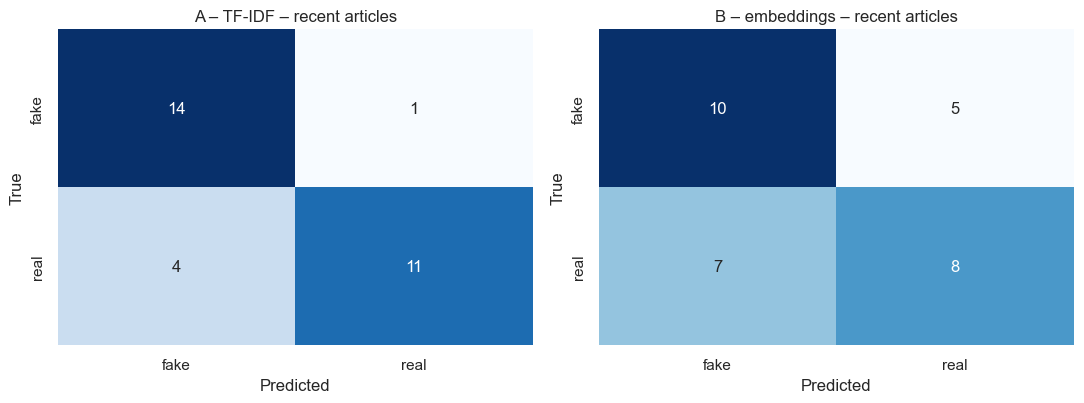

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
for ax, (name, col) in zip(axes, [("A – TF-IDF", "pred_A"), ("B – embeddings", "pred_B")]):
    sns.heatmap(confusion_matrix(y, recent[col], labels=[0, 1]), annot=True, fmt="d", cmap="Blues", ax=ax,
                xticklabels=["fake", "real"], yticklabels=["fake", "real"], cbar=False)
    ax.set_title(f"{name} – recent articles")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
plt.tight_layout()
plt.show()

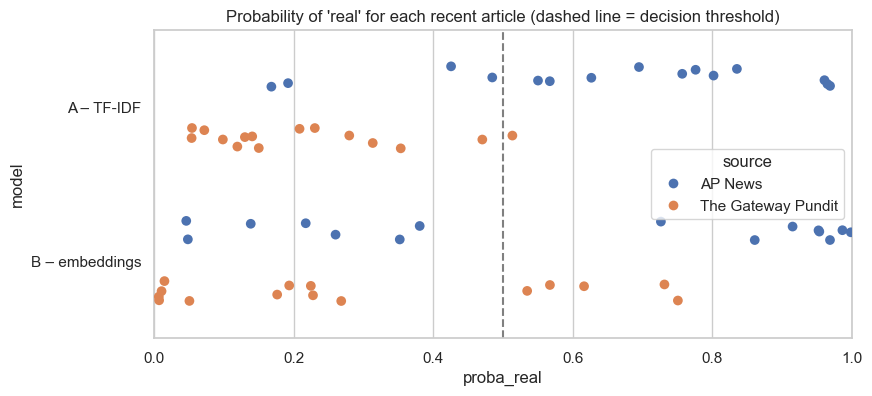

In [15]:
# Probability of 'real' given to each article
plot_df = recent.melt(id_vars=["source", "title"], value_vars=["proba_real_A", "proba_real_B"],
                      var_name="model", value_name="proba_real")
plot_df["model"] = plot_df["model"].map({"proba_real_A": "A – TF-IDF", "proba_real_B": "B – embeddings"})
plt.figure(figsize=(9, 4))
sns.stripplot(data=plot_df, x="proba_real", y="model", hue="source", dodge=True, size=7, jitter=0.15)
plt.axvline(0.5, color="grey", linestyle="--")
plt.title("Probability of 'real' for each recent article (dashed line = decision threshold)")
plt.xlim(0, 1)
plt.show()

# Part 3 – Article by article

In [16]:
table = recent[["source", "title", "proba_real_A", "proba_real_B"]].copy()
table["A correct"] = recent["pred_A"] == y
table["B correct"] = recent["pred_B"] == y
table.round(2)

,source,title,proba_real_A,proba_real_B,A correct,B correct
0,AP News,"Mideast nations ramp up efforts to avert all-out war as Israel urges Iran strikes, off...",0.97,1.00,True,True
1,AP News,Why France is sending soldiers into Ukraine and how Russia is responding,0.96,0.99,True,True
2,AP News,"Trump, Xi and Putin hold rare 3-way talks on nuclear risks but emerge with no major br...",0.96,0.97,True,True
3,AP News,Cincinnati Zoo hopes a little shake will help Fiona the hippo pass a swallowed hat,0.69,0.35,True,False
4,AP News,DOT’s Duffy said ground stop might have been shorter if L3Harris had spotted the probl...,0.48,0.26,False,False
5,AP News,High school valedictorians to get custom kicks after Sen.-elect Colom asks Nike to ‘Ju...,0.55,0.14,True,False
6,AP News,"Takeaways from Mullin’s House testimony on cyber outages, the Texas-LSU flight and imm...",0.84,0.95,True,True
7,AP News,Cornyn blocks top Justice Department official nominated for judicial vacancy in Texas,0.80,0.73,True,True
8,AP News,"Bernie Kosar marks 1 year since liver transplant, says he feels ‘happily surprised’",0.17,0.38,False,False
9,AP News,"Rob Manfred says MLB owners won’t compromise on a salary cap, leaving sport headed to ...",0.63,0.95,True,True


**Interpretation – the two models make different kinds of errors:**
- **Model A (style)** is right on all hard-news AP articles (war, diplomacy, Congress, economy) and wrong on 4 **soft-news / feature** AP articles: Bernie Kosar's transplant (0.17), the Miami Heat × GTA collaboration (0.19), the wildlife crossing (0.43), the ground stop (0.48, just under the threshold). It misses only one Gateway Pundit article (Islam projected to overtake Christianity, 0.51 – a "study" article written in a factual tone).
- **Model B (topic)** is wrong on **7 AP articles, all non-political** (hippo, valedictorians, Kosar, Miami Heat, Melinda French Gates donations, wildlife crossing, ground stop): the 2016-17 real class was almost only politics and world news, so any other subject looks "fake" to it. And it is wrong on **5 Gateway Pundit articles about Congress hearings or politicians** (Bennie Thompson 0.73, Al Green 0.75, Mullin 0.62, Cornyn 0.57, Musk 0.53): their *topic* is serious politics, so it says "real" whatever the partisan tone.
- This confirms the conclusion of notebook 3: embeddings capture **what the article is about**, TF-IDF captures **how it is written** – and on this task, how it is written is the better signal.

# Part 4 – Why does the TF-IDF model decide this way?

For one article, the contribution of a word = its TF-IDF value in the article × its coefficient in the logistic regression (function `explain_tfidf` in `src/model_utils.py`, also used by the app). We look at the misclassified articles of model A.

In [17]:
def show_explanation(row, top_n=6):
    to_real, to_fake = explain_tfidf(baseline, row["title"], row["text"], top_n)
    print(f"[{row['source']}] {row['title'][:100]}")
    print(f"   true: {LABELS[row['label']]} – proba real (A) = {row['proba_real_A']:.2f}")
    print("   pushes to REAL:", ", ".join(w for w, _ in to_real))
    print("   pushes to FAKE:", ", ".join(w for w, _ in to_fake))
    print()

for _, row in recent[recent["pred_A"] != y].iterrows():
    show_explanation(row)

[AP News] DOT’s Duffy said ground stop might have been shorter if L3Harris had spotted the problem sooner
   true: real – proba real (A) = 0.48
   pushes to REAL: said, wednesday, friday, tuesday, agency, said tuesday
   pushes to FAKE: really, get, time, morning, wire, america

[AP News] Bernie Kosar marks 1 year since liver transplant, says he feels ‘happily surprised’
   true: real – proba real (A) = 0.17
   pushes to REAL: said, wednesday, nov, news conference, television, third
   pushes to FAKE: really, like, life, time, bernie, revealed

[AP News] The Vice City Heat: Miami’s NBA team goes all in on ‘Grand Theft Auto VI’ collaboration
   true: real – proba real (A) = 0.19
   pushes to REAL: said, wednesday, tuesday, vice, city, title
   pushes to FAKE: video, even, got, like, know, way

[AP News] Over a freeway near Los Angeles, animals can roam safely thanks to world’s largest wildlife crossing
   true: real – proba real (A) = 0.43
   pushes to REAL: said, wednesday, nov, killed

**Interpretation:**
- The words pushing towards *real* are always the agency style: *said*, the days of the week, *nov*, *official*, *agency*, *news conference*.
- The 4 misclassified AP articles are pushed towards *fake* by **informal or emotional words** that are normal in a feature story: *really*, *like*, *life*, *video*, *got*, *know*, *photo*. The model learned in 2016-17 that these words belong to blogs.
- The Gateway Pundit article on Islam is pushed towards *real* by the vocabulary of world news (*expected*, *africa*, *islamic state*, *democratic*), and towards *fake* by *read* (as in *"read more"*) and by **the name of the site itself** (*gateway pundit*): the name of a source is still a clue the model can use – another kind of leak, which would not exist for an unknown fake news site.

## Same event, two sources

AP and The Gateway Pundit both covered Senator John Cornyn blocking a judicial nomination in Texas: a direct comparison of the two styles on the same facts.

In [18]:
for _, row in recent[recent["title"].str.contains("Cornyn", case=False)].iterrows():
    show_explanation(row)

[AP News] Cornyn blocks top Justice Department official nominated for judicial vacancy in Texas
   true: real – proba real (A) = 0.80
   pushes to REAL: said, wednesday, president donald, senate, senator, nov
   pushes to FAKE: sen, gop, actually, american, press, know

[The Gateway Pundit] RINO Cornyn Blocks Trump’s Last-Minute Nomination to Northern District Court in Texas
   true: fake – proba real (A) = 0.35
   pushes to REAL: said, wednesday, senate, nomination, court, told
   pushes to FAKE: president trump, gop, read, sen, trump, cnn



**Interpretation:** same facts, opposite decisions – 0.80 *real* for AP, 0.35 for The Gateway Pundit. Both share the factual words (*said*, *wednesday*, *senate*, *nomination*), but the Gateway Pundit version adds partisan markers (*RINO* in the title, *gop*, *president trump*, *read*, *cnn*). The model does not check the facts: it detects the **partisan blog style**. This is exactly how it should be presented to users: an indicator of the *style* of a source, not a fact-checker.

# Summary

1. **Data:** 30 articles collected on 19/11/2026 – 15 real from AP News (news agency) and 15 fake from The Gateway Pundit (Questionable source, Very Low factual reporting according to Media Bias/Fact Check). Labels by source, like the training dataset. The new articles show the same style differences as in 2016-17: Gateway Pundit titles have capitals (53%), *VIDEO/WATCH* (33%), `!` or `?` (27%); AP articles start with a `CITY (AP) —` dateline (73%).
2. **Results on recent articles:**

   | Model | Recent articles (2026) | Test set (2016-17) |
   |---|---|---|
   | A – TF-IDF + logistic regression | **83.3%** (real 11/15, fake 14/15) | 96.5% |
   | B – embeddings + logistic regression | **60.0%** (real 8/15, fake 10/15) | 92.7% |

3. **Generalisation:** both models lose accuracy on articles 9-10 years more recent, from sources never seen during training. The TF-IDF model resists much better (−13 points vs −33): the **blog vs agency style** it learned still exists in 2026, while the topics have changed.
4. **Errors of model A:** soft-news / feature AP articles (sports, health, lifestyle, animals) written with informal words (*really*, *like*, *video*) → predicted fake. Only one fake article missed (factual tone).
5. **Errors of model B:** any non-political real article → fake; any fake article about Congress or politicians → real. It judges the **topic**, not the reliability.
6. **Same event, two sources (Cornyn):** 0.80 real for AP vs 0.35 for The Gateway Pundit – the model reacts to partisan markers (*RINO*, *gop*, *read*), not to the facts.
7. **Limits of this test:**
   - Only 30 articles (1 article = 3.3 points): the scores are indicative.
   - One source per class, and the fake set is **right-wing only** (Occupy Democrats did not load, Natural News did not allow saving its pages): we did not test left-wing fake news.
   - Labels by source: some Gateway Pundit articles report real events with a partisan spin.
   - The model can use the **name of a known source** (*gateway pundit*) – an unknown fake news site would not have this clue.
8. **Decision for the app:** the **TF-IDF model** is the main model. The app must present the result honestly: *"this text is written like a reliable news agency / like an unreliable partisan site"*, with the words that explain the decision, and a warning that it does not check facts and is less reliable on soft news, very short texts and non-English texts.